In [1]:
import pandas as pd                      # for loading and handling the table
import matplotlib.pyplot as plt          # for plots
import seaborn as sns                    # for nicer plots (heatmap)
import joblib                            # to save the trained model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression   # swap for whatever Titanic uses
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
from google.colab import files
files.upload()   # opens a file picker, select processed.cleveland.data

Saving processed.cleveland.data to processed.cleveland.data


{'processed.cleveland.data': b'63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0\n67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2\n67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1\n37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0\n41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0\n56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0\n62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3\n57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0\n63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2\n53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1\n57.0,1.0,4.0,140.0,192.0,0.0,0.0,148.0,0.0,0.4,2.0,0.0,6.0,0\n56.0,0.0,2.0,140.0,294.0,0.0,2.0,153.0,0.0,1.3,2.0,0.0,3.0,0\n56.0,1.0,3.0,130.0,256.0,1.0,2.0,142.0,1.0,0.6,2.0,1.0,6.0,2\n44.0,1.0,2.0,120.0,263.0,0.0,0.0,173.0,0.0,0.0,1.0,0.0,7.0,0\n52.0,1.0,3.0,172.0,199.0,1.0,0.0,162.0,0.0,0.5,1.0,0.0,7.0,0\n57.0,1.0,3.0,150.0,168.0,0.0,0.0,174.0,

In [4]:
# The file has no header row, so we name the columns ourselves
cols = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach',
        'exang','oldpeak','slope','ca','thal','target']

# na_values='?' tells pandas that '?' means missing
df = pd.read_csv('processed.cleveland.data', names=cols, na_values='?')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [5]:
df.shape            # rows and columns
df.info()           # data types
df.isnull().sum()   # missing values per column (ca and thal have a few)
df.describe()       # basic stats
df['target'].value_counts()   # original target has values 0-4

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,count
target,
0,164
1,55
2,36
3,35
4,13


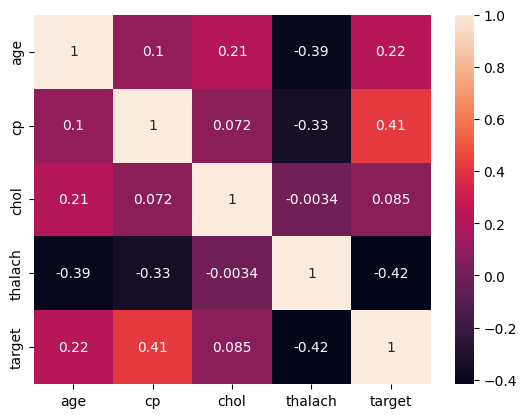

In [6]:
# Original target: 0 = healthy, 1-4 = different severities of disease.
# We only want yes/no, so anything above 0 becomes 1.
df['target'] = (df['target'] > 0).astype(int)

# Keep only the 4 chosen input attributes (assignment constraint) + target
features = ['age', 'cp', 'chol', 'thalach']
data = df[features + ['target']].dropna()   # drop rows with missing values

# Label encoding note: 'cp' is already numeric-coded (1-4),
# so no extra encoding is needed. Mention this in a markdown cell.
sns.heatmap(data.corr(), annot=True)   # shows why these features matter
plt.show()

In [7]:
X = data[features]    # inputs
y = data['target']    # what we predict

# 80% to learn from, 20% to test on; random_state makes it repeatable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)   # use the SAME algorithm as Titanic
model.fit(X_train, y_train)                 # training happens here

LogisticRegression(max_iter=1000)

In [8]:
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7377049180327869
[[22  7]
 [ 9 23]]
              precision    recall  f1-score   support

           0       0.71      0.76      0.73        29
           1       0.77      0.72      0.74        32

    accuracy                           0.74        61
   macro avg       0.74      0.74      0.74        61
weighted avg       0.74      0.74      0.74        61



In [9]:
joblib.dump(model, 'heart_model.pkl')

['heart_model.pkl']

In [11]:
files.download('heart_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>